In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
df = pd.read_csv('merged_df_raw.csv')

In [4]:
df.head()

,REGION,SETTLEMENTDATE,TOTALDEMAND,RRP,PERIODTYPE,station_number,year_local,month_local,day_local,hour_local,...,max_gust_kmh,max_gust_quality,mslp_hpa,mslp_quality,station_level_pressure_hpa,station_level_pressure_quality,aws_flag,station_name,latitude,longitude
0,NSW1,2000-09-01 00:30:00,8117.23667,36.72,TRADE,66062.0,2000.0,9.0,1.0,1.0,...,NaN,NaN,1011.3,N,1006.5,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205
1,NSW1,2000-09-01 01:00:00,7799.70000,32.92,TRADE,66062.0,2000.0,9.0,1.0,2.0,...,NaN,NaN,1011.1,N,1006.3,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205
2,NSW1,2000-09-01 01:30:00,7453.99000,27.84,TRADE,66062.0,2000.0,9.0,1.0,2.0,...,NaN,NaN,1011.3,N,1006.5,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205
3,NSW1,2000-09-01 02:00:00,7095.55333,30.62,TRADE,66062.0,2000.0,9.0,1.0,3.0,...,NaN,NaN,1011.3,N,1006.5,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205
4,NSW1,2000-09-01 02:30:00,6786.22167,33.53,TRADE,66062.0,2000.0,9.0,1.0,3.0,...,NaN,NaN,1011.2,N,1006.4,N,1.0,SYDNEY (OBSERVATORY HILL),-33.8607,151.205


In [5]:
df.dtypes

REGION                             object
SETTLEMENTDATE                     object
TOTALDEMAND                       float64
RRP                               float64
PERIODTYPE                         object
station_number                    float64
year_local                        float64
month_local                       float64
day_local                         float64
hour_local                        float64
minute_local                      float64
year_std                          float64
month_std                         float64
day_std                           float64
hour_std                          float64
minute_std                        float64
precipitation_9am_mm              float64
precipitation_quality              object
air_temperature_c                 float64
air_temperature_quality            object
wet_bulb_temp_c                   float64
wet_bulb_quality                   object
dew_point_temp_c                  float64
dew_point_quality                 

In [7]:
df.describe()

,TOTALDEMAND,RRP,station_number,year_local,month_local,day_local,hour_local,minute_local,year_std,month_std,...,dew_point_temp_c,relative_humidity_pct,wind_speed_kmh,wind_direction_deg,max_gust_kmh,mslp_hpa,station_level_pressure_hpa,aws_flag,latitude,longitude
count,1.658965e+06,1.658965e+06,1.651283e+06,1.651283e+06,1.651283e+06,1.651283e+06,1.651283e+06,1.651283e+06,1.651283e+06,1.651283e+06,...,1.649897e+06,1.649895e+06,1.238046e+06,1.236894e+06,1.211741e+06,1.648923e+06,1.648383e+06,1.612103e+06,1.651283e+06,1.651283e+06
mean,4.619879e+03,5.142330e+01,6.021096e+04,2.009928e+03,6.532510e+00,1.573475e+01,1.149949e+01,1.499716e+01,2.009928e+03,6.533028e+00,...,9.892738e+00,6.518546e+01,1.009905e+01,1.757392e+02,1.748023e+01,1.016619e+03,1.012563e+03,9.999988e-01,-3.496289e+01,1.470197e+02
std,2.848202e+03,1.912126e+02,2.638102e+04,5.636511e+00,3.448089e+00,8.791044e+00,6.924821e+00,1.500000e+01,5.636496e+00,3.448132e+00,...,5.535655e+00,1.868928e+01,7.346314e+00,1.143524e+02,1.105936e+01,7.490337e+00,7.804811e+00,4.167568e-03,4.849177e+00,5.213857e+00
min,2.189000e+01,-1.000000e+03,2.309000e+04,2.000000e+03,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,2.000000e+03,1.000000e+00,...,-2.820000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.753000e+02,9.693000e+02,0.000000e+00,-4.288970e+01,1.386216e+02
25%,1.414270e+03,2.334000e+01,4.091300e+04,2.005000e+03,4.000000e+00,8.000000e+00,5.000000e+00,0.000000e+00,2.005000e+03,4.000000e+00,...,5.800000e+00,5.300000e+01,5.400000e+00,7.000000e+01,9.400000e+00,1.012000e+03,1.007800e+03,1.000000e+00,-3.780750e+01,1.449700e+02
50%,5.131463e+03,3.441000e+01,6.606200e+04,2.010000e+03,7.000000e+00,1.600000e+01,1.100000e+01,0.000000e+00,2.010000e+03,7.000000e+00,...,9.500000e+00,6.700000e+01,9.400000e+00,1.900000e+02,1.480000e+01,1.016900e+03,1.013100e+03,1.000000e+00,-3.492110e+01,1.473278e+02
75%,6.591495e+03,5.487000e+01,8.607100e+04,2.015000e+03,1.000000e+01,2.300000e+01,1.800000e+01,3.000000e+01,2.015000e+03,1.000000e+01,...,1.400000e+01,8.000000e+01,1.480000e+01,2.700000e+02,2.410000e+01,1.021700e+03,1.017900e+03,1.000000e+00,-3.386070e+01,1.512050e+02
max,1.457986e+04,1.470000e+04,9.402900e+04,2.020000e+03,1.200000e+01,3.100000e+01,2.300000e+01,3.000000e+01,2.020000e+03,1.200000e+01,...,4.100000e+01,1.030000e+02,8.140000e+01,3.600000e+02,1.278000e+02,1.041800e+03,1.037600e+03,2.000000e+00,-2.748080e+01,1.530389e+02


In [8]:
(df.isna().mean() * 100).round(2).sort_values(ascending=False)

max_gust_kmh                      26.96
max_gust_quality                  26.96
wind_direction_quality            25.44
wind_direction_deg                25.44
wind_speed_kmh                    25.37
wind_speed_quality                25.37
aws_flag                           2.82
precipitation_quality              1.14
precipitation_9am_mm               1.14
wet_bulb_quality                   0.66
wet_bulb_temp_c                    0.66
station_level_pressure_hpa         0.64
station_level_pressure_quality     0.64
mslp_hpa                           0.61
mslp_quality                       0.61
dew_point_quality                  0.55
relative_humidity_quality          0.55
relative_humidity_pct              0.55
dew_point_temp_c                   0.55
air_temperature_c                  0.53
air_temperature_quality            0.53
station_name                       0.46
latitude                           0.46
longitude                          0.46
minute_std                         0.46


In [9]:
print(df['PERIODTYPE'].unique())         
quality_cols = [c for c in df.columns if c.endswith('_quality')]
print(df[quality_cols].apply(lambda s: s.value_counts(dropna=False)).T)

['TRADE']
                                      N     NaN
precipitation_quality           1640111   18854
air_temperature_quality         1650156    8809
wet_bulb_quality                1648074   10891
dew_point_quality               1649897    9068
relative_humidity_quality       1649895    9070
wind_speed_quality              1238046  420919
wind_direction_quality          1237005  421960
max_gust_quality                1211741  447224
mslp_quality                    1648923   10042
station_level_pressure_quality  1648383   10582


In [10]:
df = df.drop(columns=['PERIODTYPE'] + quality_cols)
df.shape

(1658965, 29)

In [11]:
n_dupe = df.duplicated(subset=['REGION', 'SETTLEMENTDATE']).sum()
print("Duplicate REGION+SETTLEMENTDATE rows:", n_dupe)

Duplicate REGION+SETTLEMENTDATE rows: 2640


In [12]:
dupes = df[df.duplicated(
    subset=['REGION', 'SETTLEMENTDATE'],
    keep=False
)]

dupes.head(20)

,REGION,SETTLEMENTDATE,TOTALDEMAND,RRP,station_number,year_local,month_local,day_local,hour_local,minute_local,...,relative_humidity_pct,wind_speed_kmh,wind_direction_deg,max_gust_kmh,mslp_hpa,station_level_pressure_hpa,aws_flag,station_name,latitude,longitude
46942,TAS1,2016-12-09 00:00:00,929.97,11.69,94029.0,2016.0,12.0,9.0,1.0,0.0,...,62.0,33.5,230.0,61.2,994.1,988.1,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278
46943,TAS1,2016-12-09 00:30:00,910.80,14.25,94029.0,2016.0,12.0,9.0,1.0,30.0,...,62.0,31.3,230.0,55.4,994.5,988.5,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278
46944,TAS1,2016-12-09 01:00:00,912.36,7.71,94029.0,2016.0,12.0,9.0,2.0,0.0,...,61.0,31.3,230.0,48.2,995.4,989.4,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278
46945,TAS1,2016-12-09 01:30:00,908.25,8.19,94029.0,2016.0,12.0,9.0,2.0,30.0,...,65.0,24.1,240.0,48.2,996.2,990.2,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278
46946,TAS1,2016-12-09 02:00:00,912.12,7.13,94029.0,2016.0,12.0,9.0,3.0,0.0,...,62.0,35.3,230.0,53.6,996.8,990.8,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278
46947,TAS1,2016-12-09 02:30:00,908.50,9.42,94029.0,2016.0,12.0,9.0,3.0,30.0,...,60.0,33.5,230.0,57.2,997.4,991.4,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278
46948,TAS1,2016-12-09 03:00:00,915.86,10.13,94029.0,2016.0,12.0,9.0,4.0,0.0,...,60.0,27.7,230.0,46.4,998.3,992.3,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278
46949,TAS1,2016-12-09 03:30:00,921.62,9.55,94029.0,2016.0,12.0,9.0,4.0,30.0,...,74.0,29.5,210.0,48.2,999.2,993.2,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278
46950,TAS1,2016-12-09 04:00:00,930.09,9.85,94029.0,2016.0,12.0,9.0,5.0,0.0,...,67.0,13.0,220.0,27.7,1000.1,994.1,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278
46951,TAS1,2016-12-09 04:30:00,942.71,17.01,94029.0,2016.0,12.0,9.0,5.0,30.0,...,63.0,24.1,220.0,44.3,1000.5,994.5,1.0,HOBART (ELLERSLIE ROAD),-42.8897,147.3278


In [13]:
dupes[['REGION', 'SETTLEMENTDATE', 'TOTALDEMAND']]

,REGION,SETTLEMENTDATE,TOTALDEMAND
46942,TAS1,2016-12-09 00:00:00,929.97
46943,TAS1,2016-12-09 00:30:00,910.80
46944,TAS1,2016-12-09 01:00:00,912.36
46945,TAS1,2016-12-09 01:30:00,908.25
46946,TAS1,2016-12-09 02:00:00,912.12
...,...,...,...
1592239,SA1,2016-11-09 21:30:00,1350.44
1592240,SA1,2016-11-09 22:00:00,1295.71
1592241,SA1,2016-11-09 22:30:00,1237.32
1592242,SA1,2016-11-09 23:00:00,1211.09


In [14]:
df['datetime_std'] = pd.to_datetime(df['SETTLEMENTDATE'])

local_cols = ['year_local', 'month_local', 'day_local', 'hour_local', 'minute_local']
has_local = df[local_cols].notna().all(axis=1)

df['datetime_local'] = pd.NaT
df.loc[has_local, 'datetime_local'] = pd.to_datetime(dict(
    year=df.loc[has_local, 'year_local'].astype(int),
    month=df.loc[has_local, 'month_local'].astype(int),
    day=df.loc[has_local, 'day_local'].astype(int),
    hour=df.loc[has_local, 'hour_local'].astype(int),
    minute=df.loc[has_local, 'minute_local'].astype(int),
))
df.loc[~has_local, 'datetime_local'] = df.loc[~has_local, 'datetime_std']  # rare fallback

df = df.drop(columns=['SETTLEMENTDATE'] + local_cols +
             ['year_std', 'month_std', 'day_std', 'hour_std', 'minute_std'])

df['hour'] = df['datetime_local'].dt.hour
df['day_of_week'] = df['datetime_local'].dt.dayofweek   # 0=Mon ... 6=Sun
df['is_weekend'] = df['day_of_week'].isin([5, 6])

df[['REGION', 'datetime_local', 'hour', 'day_of_week', 'is_weekend']].head()

,REGION,datetime_local,hour,day_of_week,is_weekend
0,NSW1,2000-09-01 01:30:00,1,4,False
1,NSW1,2000-09-01 02:00:00,2,4,False
2,NSW1,2000-09-01 02:30:00,2,4,False
3,NSW1,2000-09-01 03:00:00,3,4,False
4,NSW1,2000-09-01 03:30:00,3,4,False


In [15]:
df = df.sort_values(['REGION', 'datetime_std']).reset_index(drop=True)

before = df['air_temperature_c'].isna().sum()
df['air_temperature_c'] = (
    df.groupby('REGION')['air_temperature_c']
      .transform(lambda x: x.interpolate(method='linear', limit=4, limit_area='inside'))
)
after = df['air_temperature_c'].isna().sum()
print(f"air_temperature_c missing: {before} -> {after} ({after/len(df)*100:.2f}%)")

air_temperature_c missing: 8809 -> 4258 (0.26%)


In [16]:
print("Exact duplicate rows:", df.duplicated().sum())
n_dupe_keys = df.duplicated(subset=['REGION', 'datetime_std']).sum()
print("Duplicate REGION+datetime_std:", n_dupe_keys)
print("Negative/zero TOTALDEMAND:", (df['TOTALDEMAND'] <= 0).sum())
print()
print("Remaining missing values (%):")
print((df.isna().mean() * 100).round(2).sort_values(ascending=False).head(10))

Exact duplicate rows: 0
Duplicate REGION+datetime_std: 2640
Negative/zero TOTALDEMAND: 0

Remaining missing values (%):
max_gust_kmh                  26.96
wind_direction_deg            25.44
wind_speed_kmh                25.37
aws_flag                       2.82
precipitation_9am_mm           1.14
wet_bulb_temp_c                0.66
station_level_pressure_hpa     0.64
mslp_hpa                       0.61
dew_point_temp_c               0.55
relative_humidity_pct          0.55
dtype: float64


## EDA

In [20]:
sns.set_theme(style='whitegrid', rc={'axes.grid': True, 'grid.alpha': 0.3})

df = df.copy()  # avoids SettingWithCopyWarning from the column-reorder slice above

df['demand_z'] = df.groupby('REGION')['TOTALDEMAND'].transform(lambda x: (x - x.mean()) / x.std())
df[['REGION', 'hour', 'TOTALDEMAND', 'demand_z', 'air_temperature_c']].head()

,REGION,hour,TOTALDEMAND,demand_z,air_temperature_c
0,NSW1,1,6763.57000,-1.152460,16.8
1,NSW1,2,6386.10167,-1.430660,16.5
2,NSW1,2,5990.79500,-1.722007,16.4
3,NSW1,3,5655.97667,-1.968773,16.3
4,NSW1,3,5283.83667,-2.243045,16.2


In [21]:
df['temp_group'] = pd.cut(df['air_temperature_c'], bins=[-np.inf, 15, 25, np.inf],
                          labels=['Cold (<15°C)', 'Mild (15-25°C)', 'Hot (>25°C)'])

### Daily cycle of demand and temperature


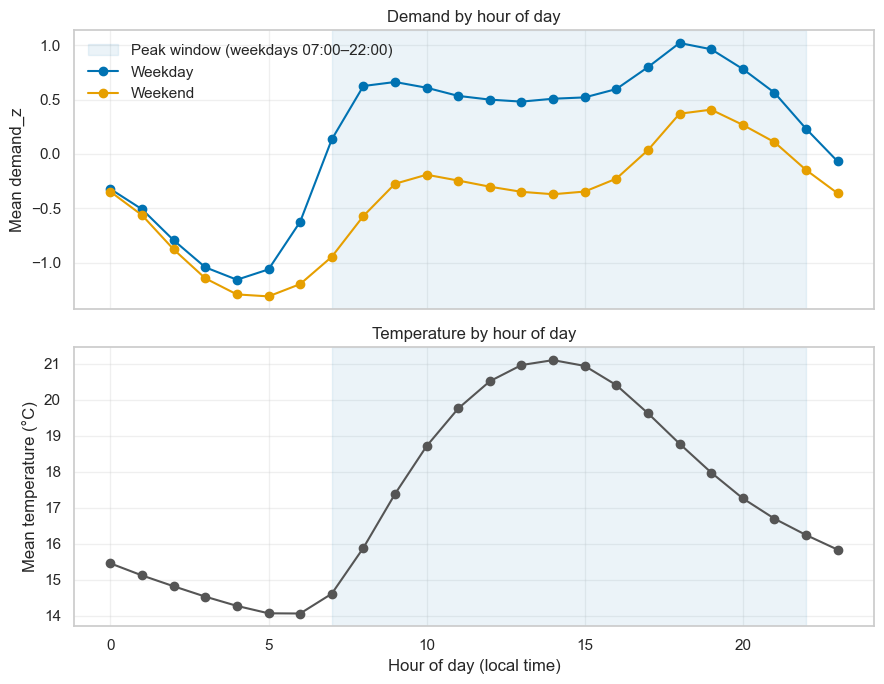

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

by_hour = df.groupby(['hour', 'is_weekend'])['demand_z'].mean().unstack()
axes[0].axvspan(7, 22, color='#0072B2', alpha=0.08, label='Peak window (weekdays 07:00–22:00)')
axes[0].plot(by_hour.index, by_hour[False], marker='o', color='#0072B2', label='Weekday')
axes[0].plot(by_hour.index, by_hour[True], marker='o', color='#E69F00', label='Weekend')
axes[0].set_ylabel('Mean demand_z')
axes[0].set_title('Demand by hour of day')
axes[0].legend(loc='upper left', frameon=False)

temp = df.groupby('hour')['air_temperature_c'].mean()
axes[1].axvspan(7, 22, color='#0072B2', alpha=0.08)
axes[1].plot(temp.index, temp.values, marker='o', color='#555555')
axes[1].set_ylabel('Mean temperature (°C)')
axes[1].set_xlabel('Hour of day (local time)')
axes[1].set_title('Temperature by hour of day')

plt.tight_layout()
plt.show()

### Demand by hour and temperature (all states)


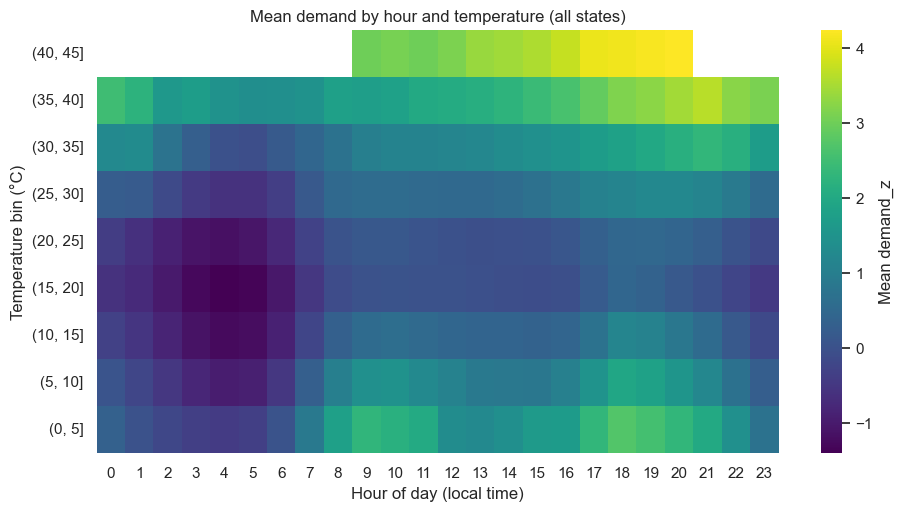

In [23]:
df['temp_bin'] = pd.cut(df['air_temperature_c'], range(0, 46, 5))
table = df.pivot_table(index='temp_bin', columns='hour', values='demand_z', observed=True).sort_index(ascending=False)

plt.figure(figsize=(11, 5.5))
sns.heatmap(table, cmap='viridis', cbar_kws={'label': 'Mean demand_z'})
plt.title('Mean demand by hour and temperature (all states)')
plt.xlabel('Hour of day (local time)')
plt.ylabel('Temperature bin (°C)')
plt.grid(False)
plt.show()

### Demand against temperature at different times of day


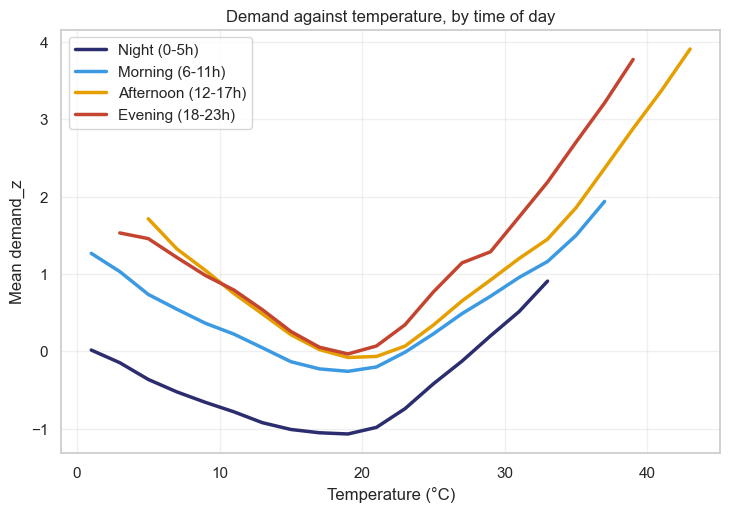

In [24]:
df['time_of_day'] = pd.cut(df['hour'], [-1, 5, 11, 17, 23],
                           labels=['Night (0-5h)', 'Morning (6-11h)', 'Afternoon (12-17h)', 'Evening (18-23h)'])
df['temp_2c'] = (df['air_temperature_c'] // 2) * 2 + 1          # centre of each 2°C bin

curve = df.groupby(['time_of_day', 'temp_2c'], observed=True)['demand_z'].agg(['mean', 'count']).reset_index()
curve = curve[curve['count'] >= 200]                            # skip bins with few readings

plt.figure(figsize=(8.5, 5.5))
sns.lineplot(data=curve, x='temp_2c', y='mean', hue='time_of_day', linewidth=2.5,
             palette=['#2b2d6e', '#3b9ae1', '#e69f00', '#c4442f'])
plt.title('Demand against temperature, by time of day')
plt.xlabel('Temperature (°C)')
plt.ylabel('Mean demand_z')
plt.legend(title=None)
plt.show()

### Cold, mild and hot weather through the day

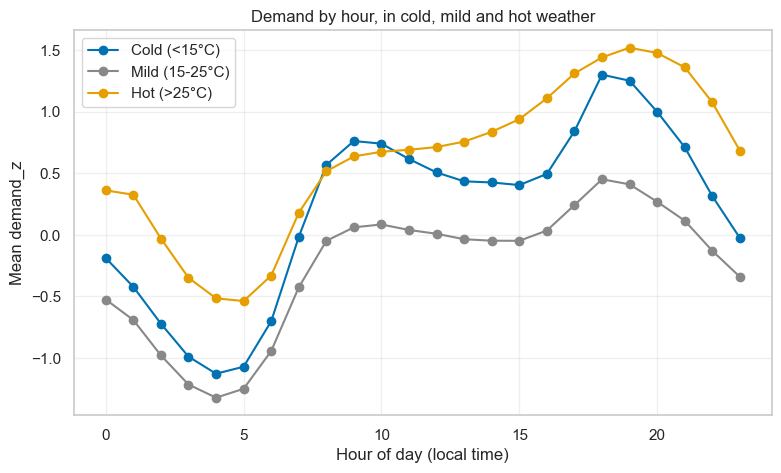

In [25]:
by_group = df.groupby(['hour', 'temp_group'], observed=True)['demand_z'].mean().unstack()

by_group.plot(figsize=(9, 5), marker='o', color=['#0072B2', '#888888', '#E69F00'])
plt.title('Demand by hour, in cold, mild and hot weather')
plt.xlabel('Hour of day (local time)')
plt.ylabel('Mean demand_z')
plt.legend(title=None)
plt.show()

### Size of the temperature effect by hour

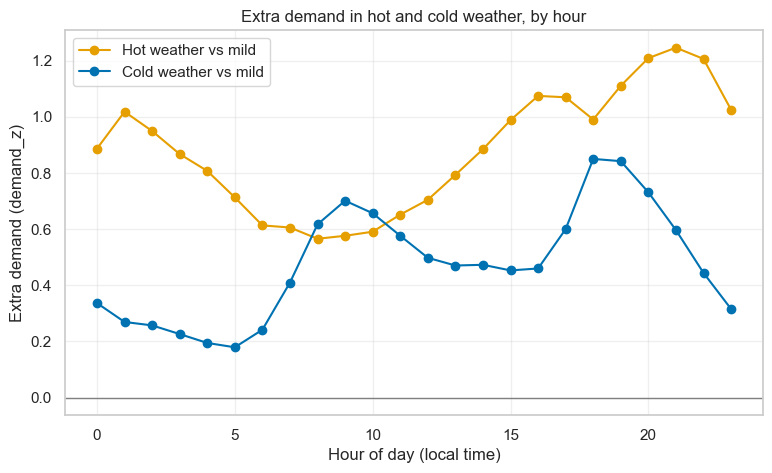

In [27]:
by_group = df.groupby(['hour', 'temp_group'], observed=True)['demand_z'].mean().unstack()
effect = pd.DataFrame({'Hot weather vs mild': by_group['Hot (>25°C)'] - by_group['Mild (15-25°C)'],
                       'Cold weather vs mild': by_group['Cold (<15°C)'] - by_group['Mild (15-25°C)']})

effect.plot(figsize=(9, 5), marker='o', color=['#E69F00', '#0072B2'])
plt.axhline(0, color='grey', linewidth=1)
plt.title('Extra demand in hot and cold weather, by hour')
plt.xlabel('Hour of day (local time)')
plt.ylabel('Extra demand (demand_z)')
plt.legend(title=None)
plt.show()

In [ ]:
### Size of the temperature effect by hour, per state


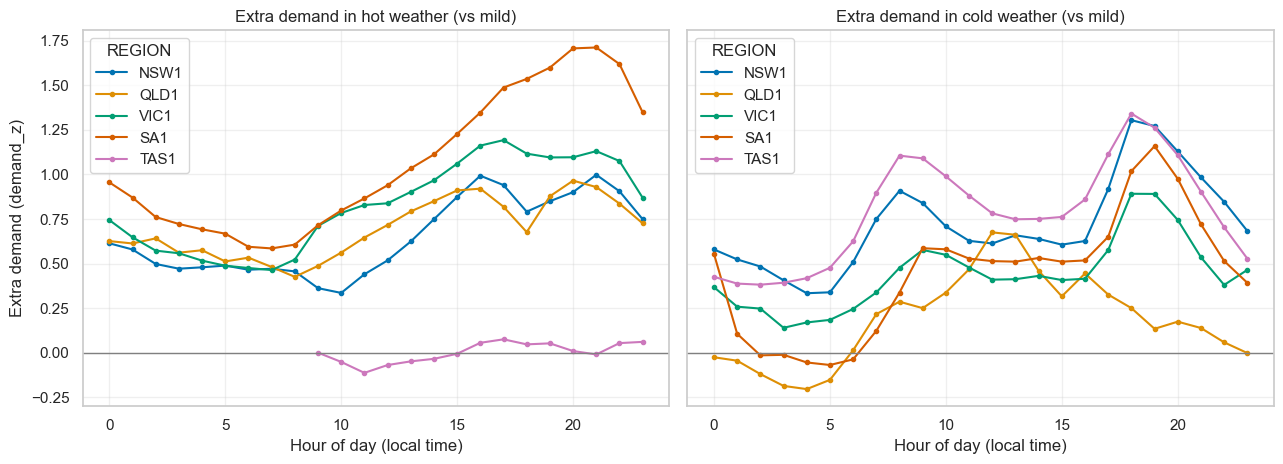

In [32]:
stats = df.groupby(['REGION', 'hour', 'temp_group'], observed=True)['demand_z'].agg(['mean', 'count'])
g = stats['mean'].where(stats['count'] >= 30).unstack()          # ignore groups with fewer than 30 readings
hot = (g['Hot (>25°C)'] - g['Mild (15-25°C)']).unstack(0)[['NSW1', 'QLD1', 'VIC1', 'SA1', 'TAS1']]
cold = (g['Cold (<15°C)'] - g['Mild (15-25°C)']).unstack(0)[['NSW1', 'QLD1', 'VIC1', 'SA1', 'TAS1']]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
hot.plot(ax=axes[0], marker='o', markersize=3, color=sns.color_palette('colorblind', 5),
         title='Extra demand in hot weather (vs mild)')
cold.plot(ax=axes[1], marker='o', markersize=3, color=sns.color_palette('colorblind', 5),
          title='Extra demand in cold weather (vs mild)')
for ax in axes:
    ax.axhline(0, color='grey', linewidth=1)
    ax.set(xlabel='Hour of day (local time)')
axes[0].set_ylabel('Extra demand (demand_z)')
plt.tight_layout()
plt.show()

### Heatmap per state

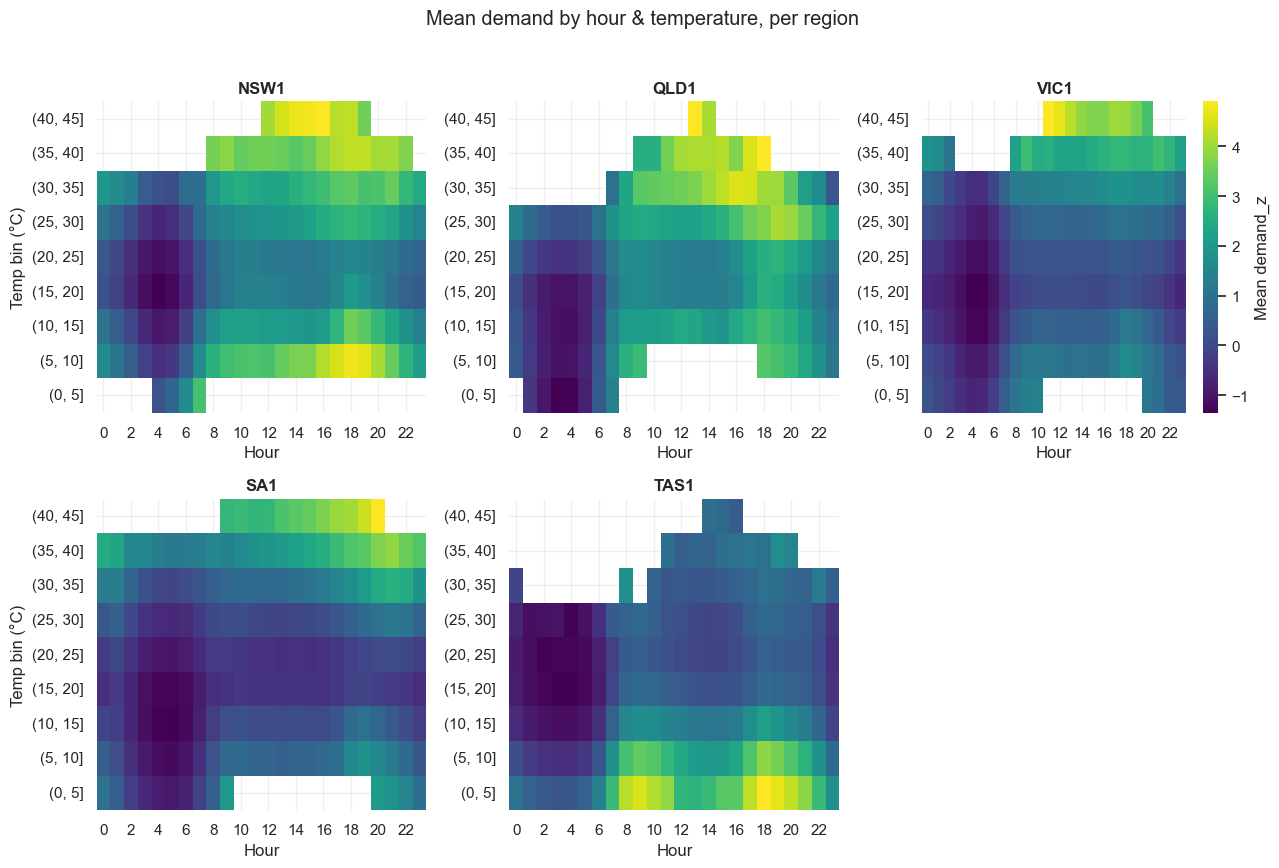

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
axes = axes.flatten()

for i, state in enumerate(['NSW1', 'QLD1', 'VIC1', 'SA1', 'TAS1']):
    table = (df[df['REGION'] == state]
             .pivot_table(index='temp_bin', columns='hour', values='demand_z', observed=True)
             .sort_index(ascending=False))
    sns.heatmap(table, cmap='viridis', ax=axes[i], cbar=(i == 2),
                cbar_kws={'label': 'Mean demand_z'} if i == 2 else None)
    axes[i].set_title(state, fontweight='bold')
    axes[i].set_xlabel('Hour')
    axes[i].set_ylabel('Temp bin (°C)' if i % 3 == 0 else '')

axes[-1].set_visible(False)
fig.suptitle('Mean demand by hour & temperature, per region', y=1.02)
plt.tight_layout()
plt.show()